## Segundo paso: análisar los dataset .csv de (AAEC, ArGPT, MTC, AASS)

In [11]:
import pandas as pd
from tabulate import tabulate
import networkx as nx
import matplotlib.pyplot as plt
from networkx.drawing.nx_pydot import graphviz_layout

In [2]:
result_path = "./results/minimal_v5/"
# path_minimal = "./dataset_minimal/"

In [20]:
def di_graph(text_id, G):

    pos = graphviz_layout(G, prog="dot")

    plt.figure(figsize=(14, 10))
    
    # Separar aristas por tipo de relación
    edges_support = [(u, v) for u, v, d in G.edges(data=True)
                    if d.get("label") == "support"]

    edges_attack = [(u, v) for u, v, d in G.edges(data=True)
                    if d.get("label") == "attack"]

    # Dibujar nodos
    nx.draw_networkx_nodes(G, pos, node_color="lightblue", node_size=1500)

    # Dibujar etiquetas de nodos
    nx.draw_networkx_labels(G, pos, font_size=9)

    # Dibujar aristas
    nx.draw_networkx_edges(G, pos, edgelist=edges_support,
                        edge_color="blue", arrows=True, arrowsize=15)

    nx.draw_networkx_edges(G, pos, edgelist=edges_attack,
                        edge_color="red", arrows=True, arrowsize=15)

    # Mostrar etiquetas de aristas
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels,
                                font_size=9, rotate=False)

    plt.show()

In [3]:
def plot_grafo(text_id, G):
    # Cor por nó
    color_nodo = {
        "MajorClaim" : "#e74c3c",   # Vermelho
        "Claim"      : "#3498db",   # Azul
        "Premise"    : "#2ecc71",   # Verde
    }
    node_colors = [
        color_nodo.get(G.nodes[n].get("component", ""), "#95a5a6")
        for n in G.nodes()
    ]

    colores_label = {
        "support" : "#27ae60",   # Verde oscuro
        "attack"  : "#c0392b",   # Vermelho oscuro
    }
    edge_colors   = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]
    
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, seed=42, k=30, iterations=100)
    
    # Etiquetas de nodos con ID + tipo de componente
    node_labels = {
        n: f"{n}\n{G.nodes[n].get('component', '')}"
        for n in G.nodes()
    }

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2000)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_color="black", font_size=8, font_weight="bold")
    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        arrows=True, arrowsize=25, arrowstyle="-|>",
        width=2, connectionstyle="arc3,rad=0.1",
        min_source_margin=30, min_target_margin=30,
    )
    
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7, font_color="darkgreen")
    
    from matplotlib.lines import Line2D
    leyenda = [
        Line2D([0], [0], color="green", linewidth=2, label="support"),
        Line2D([0], [0], color="red",   linewidth=2, label="attack"),
        Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
    ]
    plt.legend(handles=leyenda, loc="upper left", fontsize=9)
    plt.title(f"Grafo argumentativo: {text_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### Dataset

In [4]:
# Cargar el DataFrame
df_cdcp = pd.read_pickle(result_path + "CDCP_Minimal_Grafo.pkl")
df_aaec = pd.read_pickle(result_path + "AAEC_Minimal_Grafo.pkl")
df_argpt = pd.read_pickle(result_path + "ArGPT_Minimal_Grafo.pkl")
df_mtc = pd.read_pickle(result_path + "MTC_Minimal_Grafo.pkl")
df_aasd = pd.read_pickle(result_path + "AASD_Minimal_Grafo.pkl")

In [39]:
df = df_mtc
df

,text_id,seg,info,graph,n_nodes,n_edges,n_comp,n_isolates
0,MTC_b001,5,minimalist_labels labels_relation source_i...,"(MTC_b001_0, MTC_b001_1, MTC_b001_2, MTC_b001_...",5,4,1,0
1,MTC_b002,5,minimalist_labels labels_relation source_i...,"(MTC_b002_0, MTC_b002_1, MTC_b002_2, MTC_b002_...",5,4,1,0
2,MTC_b003,5,minimalist_labels labels_relation source_i...,"(MTC_b003_0, MTC_b003_1, MTC_b003_2, MTC_b003_...",5,4,1,0
3,MTC_b004,5,minimalist_labels labels_relation source_i...,"(MTC_b004_0, MTC_b004_1, MTC_b004_2, MTC_b004_...",5,4,1,0
4,MTC_b005,5,minimalist_labels labels_relation source_i...,"(MTC_b005_0, MTC_b005_1, MTC_b005_2, MTC_b005_...",5,4,1,0
...,...,...,...,...,...,...,...,...
107,MTC_k024,7,minimalist_labels labels_relation source_i...,"(MTC_k024_0, MTC_k024_1, MTC_k024_2, MTC_k024_...",7,6,1,0
108,MTC_k025,5,minimalist_labels labels_relation source_i...,"(MTC_k025_0, MTC_k025_1, MTC_k025_2, MTC_k025_...",5,4,1,0
109,MTC_k027,4,minimalist_labels labels_relation source_i...,"(MTC_k027_0, MTC_k027_1, MTC_k027_2, MTC_k027_3)",4,3,1,0
110,MTC_k029,4,minimalist_labels labels_relation source_i...,"(MTC_k029_0, MTC_k029_1, MTC_k029_2, MTC_k029_3)",4,3,1,0


In [40]:
id_text_busca = "MTC_k024"
columna = "text_id"
result = df[df[columna] == id_text_busca]
result

,text_id,seg,info,graph,n_nodes,n_edges,n_comp,n_isolates
107,MTC_k024,7,minimalist_labels labels_relation source_i...,"(MTC_k024_0, MTC_k024_1, MTC_k024_2, MTC_k024_...",7,6,1,0


In [41]:
result_info = result.iloc[0]
result_info["info"]
# print(tabulate(result_info["info"].reset_index(), headers='keys', tablefmt='rounded_outline', showindex=False))

,minimalist_labels,labels_relation,source_id,label_component_source,minimal_label_component_source,target_id,label_component_target,minimal_label_component_target
0,attack,reb,MTC_k024_1,opp,Premise,MTC_k024_0,pro,MajorClaim
1,support,sup,MTC_k024_2,pro,Premise,MTC_k024_0,pro,MajorClaim
2,support,sup,MTC_k024_3,pro,Premise,MTC_k024_0,pro,MajorClaim
3,support,sup,MTC_k024_4,pro,Premise,MTC_k024_0,pro,MajorClaim
4,support,sup,MTC_k024_5,pro,Premise,MTC_k024_4,pro,Premise
5,support,sup,MTC_k024_6,pro,Premise,MTC_k024_0,pro,MajorClaim


### Caracteristicas de grafo

In [24]:
# Numeros de nodos y componentes
df_comparacion = df[
    (df["n_isolates"] != 0)
]
conteo = df_comparacion.groupby("n_comp").size()
lista = conteo.to_dict()
print(df_comparacion.shape)
print("Lista de componentes: ",lista)
df_comparacion

(616, 8)
Lista de componentes:  {2: 134, 3: 114, 4: 85, 5: 61, 6: 39, 7: 46, 8: 24, 9: 27, 10: 20, 11: 14, 12: 13, 13: 7, 14: 2, 15: 8, 16: 2, 17: 5, 18: 1, 19: 2, 20: 4, 21: 3, 22: 1, 23: 2, 24: 1, 27: 1}


,text_id,seg,info,graph,n_nodes,n_edges,n_comp,n_isolates
0,CDCP_00194,3,minimalist_labels labels_relation source...,"(CDCP_00194_0, CDCP_00194_1, CDCP_00194_2)",3,1,2,1
2,CDCP_00196,5,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00196_0, CDCP_00196_1, CDCP_00196_2, CDC...",5,0,5,5
3,CDCP_00197,4,minimalist_labels labels_relation source...,"(CDCP_00197_0, CDCP_00197_1, CDCP_00197_2, CDC...",4,1,3,2
4,CDCP_00198,4,minimalist_labels labels_relation source...,"(CDCP_00198_0, CDCP_00198_1, CDCP_00198_2, CDC...",4,1,3,2
5,CDCP_00199,2,"Empty DataFrame Columns: [minimalist_labels, l...","(CDCP_00199_0, CDCP_00199_1)",2,0,2,2
...,...,...,...,...,...,...,...,...
725,CDCP_01411,15,minimalist_labels labels_relation sourc...,"(CDCP_01411_0, CDCP_01411_1, CDCP_01411_2, CDC...",15,8,7,3
726,CDCP_01412,15,minimalist_labels labels_relation sourc...,"(CDCP_01412_0, CDCP_01412_1, CDCP_01412_2, CDC...",15,7,8,5
727,CDCP_01414,12,minimalist_labels labels_relation source...,"(CDCP_01414_0, CDCP_01414_1, CDCP_01414_2, CDC...",12,2,10,8
728,CDCP_01417,18,minimalist_labels labels_relation sourc...,"(CDCP_01417_0, CDCP_01417_1, CDCP_01417_2, CDC...",18,4,14,11


In [11]:
# Caracteristicas del grafo
acyclic = "acyclic"
cycles = "cycles"
is_tree = "tree"
is_arborescence = "arborescence"
nodes_roots = "n_roots"

# Aciclico e ciclos
df_comparacion[acyclic] = df_comparacion["graph"].apply(lambda graph: nx.is_directed_acyclic_graph(graph))
df_comparacion[cycles] = df_comparacion["graph"].apply(lambda graph: list(nx.simple_cycles(graph)))

# Arbol
df_comparacion[is_tree] = df_comparacion["graph"].apply(lambda graph: nx.is_tree(graph))
df_comparacion[is_arborescence] = df_comparacion["graph"].apply(lambda graph: nx.is_arborescence(graph))

#Numero de nodos raiz
df_comparacion[nodes_roots] = df_comparacion["graph"].apply(lambda G: sum(1 for _, grado in G.in_degree() if grado == 0))

df_comparacion

/tmp/ipykernel_202522/2155539133.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_comparacion[acyclic] = df_comparacion["graph"].apply(lambda graph: nx.is_directed_acyclic_graph(graph))
/tmp/ipykernel_202522/2155539133.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_comparacion[cycles] = df_comparacion["graph"].apply(lambda graph: list(nx.simple_cycles(graph)))
/tmp/ipykernel_202522/2155539133.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Tr

,text_id,seg,info,graph,n_nodes,n_edges,n_comp,n_isolates,acyclic,cycles,tree,arborescence,n_roots
185,AAEC_186,18,minimalist_labels labels_relation source...,"(AAEC_186_0, AAEC_186_1, AAEC_186_2, AAEC_186_...",18,16,2,1,True,[],False,False,2
285,AAEC_286,25,minimalist_labels labels_relation source...,"(AAEC_286_0, AAEC_286_1, AAEC_286_2, AAEC_286_...",25,28,2,1,True,[],False,False,3


In [161]:
# df_acyclic = df_comparacion[df_comparacion[acyclic].apply(lambda x: x == True)]
# df_acyclic.shape
# df_tree = df_comparacion[df_comparacion[is_tree].apply(lambda x: x == True)]
# df_tree.shape
df_n_root = df_comparacion[df_comparacion[nodes_roots].apply(lambda x: x != 1)]
df_n_root

,text_id,seg,info,graph,n_nodes,n_edges,n_comp,n_isolates,acyclic,cycles,tree,arborescence,n_roots
31,CDCP_00240,5,minimalist_labels labels_relation source...,"(CDCP_00240_0, CDCP_00240_1, CDCP_00240_2, CDC...",5,5,1,0,True,[],False,False,2
62,CDCP_00344,4,minimalist_labels labels_relation source...,"(CDCP_00344_0, CDCP_00344_1, CDCP_00344_2, CDC...",4,4,1,0,True,[],False,False,2
109,CDCP_00400,7,minimalist_labels labels_relation source...,"(CDCP_00400_0, CDCP_00400_1, CDCP_00400_2, CDC...",7,7,1,0,True,[],False,False,2
114,CDCP_00406,5,minimalist_labels labels_relation source...,"(CDCP_00406_0, CDCP_00406_1, CDCP_00406_2, CDC...",5,4,1,0,True,[],True,False,2
273,CDCP_00649,4,minimalist_labels labels_relation source...,"(CDCP_00649_0, CDCP_00649_1, CDCP_00649_2, CDC...",4,4,1,0,True,[],False,False,2
338,CDCP_00762,5,minimalist_labels labels_relation source...,"(CDCP_00762_0, CDCP_00762_1, CDCP_00762_2, CDC...",5,4,1,0,True,[],True,False,2
339,CDCP_00763,3,minimalist_labels labels_relation source...,"(CDCP_00763_0, CDCP_00763_1, CDCP_00763_2)",3,2,1,0,True,[],True,False,2
562,CDCP_01147,3,minimalist_labels labels_relation source...,"(CDCP_01147_0, CDCP_01147_1, CDCP_01147_2)",3,2,1,0,True,[],True,False,2
647,CDCP_01283,6,minimalist_labels labels_relation source...,"(CDCP_01283_0, CDCP_01283_1, CDCP_01283_2, CDC...",6,6,1,0,True,[],False,False,3
677,CDCP_01329,4,minimalist_labels labels_relation source...,"(CDCP_01329_0, CDCP_01329_1, CDCP_01329_2, CDC...",4,4,1,0,True,[],False,False,2


/tmp/ipykernel_298845/892015657.py:3: DeprecationWarning: nx.nx_pydot.graphviz_layout depends on the pydot package, which has known issues and is not actively maintained. Consider using nx.nx_agraph.graphviz_layout instead.

See https://github.com/networkx/networkx/issues/5723
  pos = graphviz_layout(G, prog="dot")


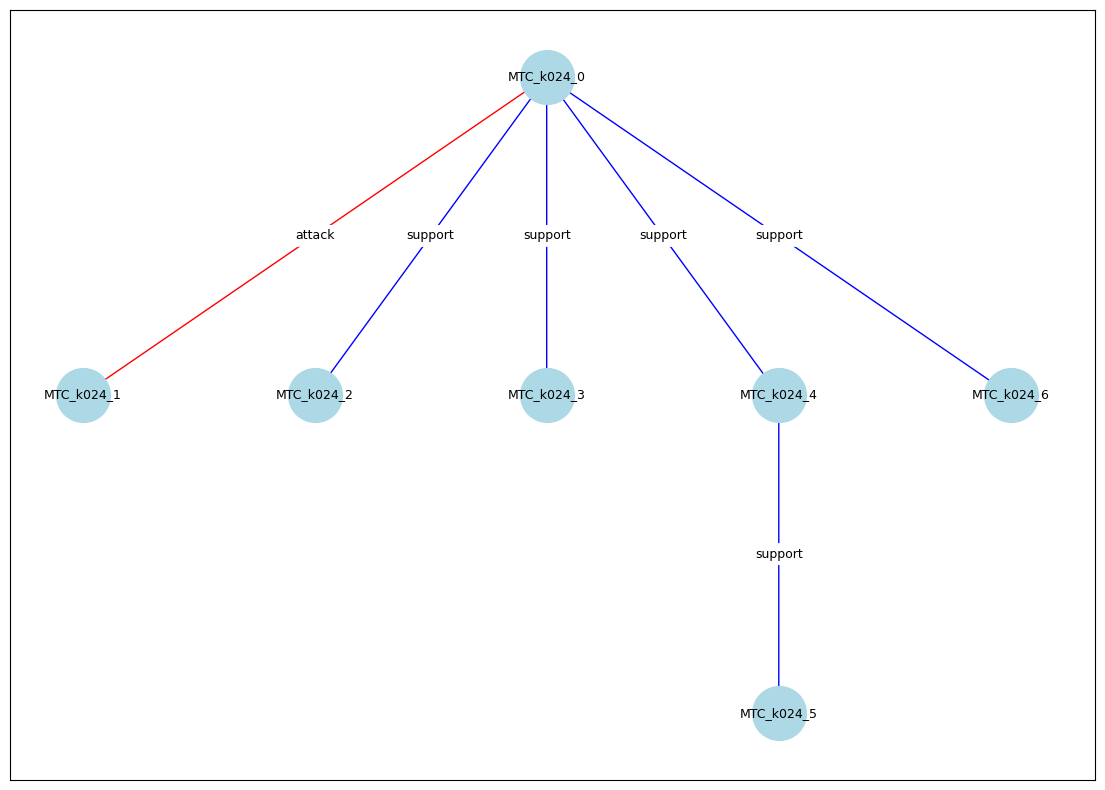

In [42]:
# plot_grafo(id_text_busca, result_info["graph"])
di_graph(id_text_busca, result_info["graph"])

## Resulatado de la Dataframe Summary minimal

In [133]:
df_resultados = pd.read_pickle(result_path + "dataframe_summary.pkl")
df_resultados
print(tabulate(df_resultados, headers='keys', tablefmt='rounded_outline', showindex=True))

╭──────────┬──────────────────┬────────────┬───────────────────┬──────────┬────────────┬──────────────────────┬──────────╮
│          │   total_text_arg │   isolados │ subgrafos         │   conexo │   aciclico │ nos_raiz             │   arvore │
├──────────┼──────────────────┼────────────┼───────────────────┼──────────┼────────────┼──────────────────────┼──────────┤
│ CDCP     │              730 │        616 │ 2: 19, 3: 3, 4: 1 │       91 │         91 │ 1: 81, 2: 9, 3: 1    │       74 │
│ AAEC     │              402 │          2 │                   │      400 │        400 │ 1: 71, 2: 311, 3: 18 │       71 │
│ ArGPT    │              172 │         44 │ 2: 21, 3: 6, 4: 1 │      100 │          6 │ 0: 14, 1: 17, 2: 28,
3: 23, 4: 10, 5: 7,
6: 1                      │        1 │
│ MTC      │              112 │          0 │                   │      112 │        112 │ 1: 112               │      112 │
│ AASD     │               60 │          0 │                   │       60 │         60 │ 1: 6